# Contrast enhancement: CLAHE and high-pass

This notebook tests two contrast enhancements (`scripts/enhance_contrast.py`, functions in
`src/utils/augmentation.py`) on NISAR tiles. The question: **do they make crevasses easier to
see?**

Steps:
1. Import libraries.
2. Definition of a tile.
3. Sample images and tiles.
4. CLAHE with several `clip_limit` values, one figure per tile.
5. High-pass with several `sigma` values, one figure per tile.
6. Apply the chosen parameters to the final frame and tiles, and save the results.

## 1. Import libraries

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.image import imsave

sys.path.insert(
    0, str(Path.cwd().parent / "scripts")
)  # so we can import enhance_contrast

import enhance_contrast

from utils.augmentation import clahe, high_pass

## 2. Definition of a tile

A tile is a 4096 x 4096 array of `uint8` gray levels (the radar backscatter in dB, stretched to
0-255). Gray level **0 means nodata** (outside the radar swath), and 1-255 is real data. `clahe()`
and `high_pass()` expect this format.

A tile is identified by its **frame** (the `.h5` file) and its **row and column** in the
4096-pixel grid. Tiles are cut with the same code as Label Studio
(`labelstudio/tileserver/tileserver.py`), so a tile here
is the same patch you see when labeling.

In [ ]:
image_dir = enhance_contrast.DEFAULT_IMAGE_DIR
output_dir = enhance_contrast.DEFAULT_OUTPUT_DIR
tile_size = enhance_contrast.TILE_SIZE

tileserver = enhance_contrast.load_tileserver(image_dir, output_dir / "stats_cache")

## 3. Sample images and tiles

The tiles used to try the parameters are chosen at random, with the same functions as the script
(`choose_frames` and `choose_tiles` in `scripts/enhance_contrast.py`). Change `SEED` to get a
different sample, or keep it to get the same tiles again. `N_FRAMES` is the number of random
frames and `N_TILES` is the number of random tiles in each frame (only tiles with enough valid
data can be chosen).

Look at the sample and check that it shows crevasses. If a sample has none, try another `SEED`.

In [ ]:
SEED = 0  # same seed, same sample
N_FRAMES = 5  # random frames
N_TILES = 2  # random tiles per frame

frames = enhance_contrast.choose_frames(
    enhance_contrast.find_frames(image_dir), N_FRAMES, SEED
)
chosen = enhance_contrast.choose_tiles(tileserver, frames, N_TILES, SEED)

sample_tiles = {}  # label -> tile
for sample_frame, stats, tile_info in chosen:
    row, col = tile_info["row"], tile_info["col"]
    label = f"{sample_frame.name[:30]}, tile ({row}, {col})"
    sample_tiles[label] = tileserver.render_tile(
        sample_frame, stats, tile_size, row, col
    )
    print(sample_frame.name, "row", row, "col", col)

## 4. CLAHE (Contrast Limited Adaptive Histogram Equalization)

CLAHE stretches the contrast in small local windows, so faint features in a dull area get brighter
too. `clip_limit` stops it from over-amplifying noise: higher means stronger contrast, and also
more speckle noise. One figure per tile: the input and the output for each `clip_limit`.

In [ ]:
clip_limits = [0.005, 0.01, 0.02, 0.05]

for label, tile in sample_tiles.items():
    fig, axes = plt.subplots(2, 3, figsize=(21, 14))
    axes[0, 0].imshow(tile, cmap="gray", vmin=0, vmax=255)
    axes[0, 0].set_title(f"{label}: input", fontsize=16, pad=12)
    for ax, clip_limit in zip(axes.flat[1:], clip_limits):
        ax.imshow(clahe(tile, clip_limit), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"CLAHE, clip_limit={clip_limit}", fontsize=16, pad=12)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 5. High-pass filtering

A Gaussian blur keeps only the slow, large-scale brightness changes. Subtracting it from the
original leaves the small features, like crevasses. `sigma` is the blur size in pixels: features
much smaller than `sigma` are kept. A small `sigma` can erase wide features, because the blur
follows them and subtracting it removes them, while thin cracks are kept. A large `sigma` keeps the
wide features too, but it also leaves more of the large-scale brightness changes in the result.
One figure per tile: the input and the output for each `sigma`.

In [ ]:
sigmas = [10, 25, 50, 100]

for label, tile in sample_tiles.items():
    fig, axes = plt.subplots(2, 3, figsize=(21, 14))
    axes[0, 0].imshow(tile, cmap="gray", vmin=0, vmax=255)
    axes[0, 0].set_title(f"{label}: input", fontsize=16, pad=12)
    for ax, sigma in zip(axes.flat[1:], sigmas):
        ax.imshow(high_pass(tile, sigma), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"High-pass, sigma={sigma}", fontsize=16, pad=12)
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 6. Apply the chosen parameters

After choosing the parameters for both methods, the team decided to apply them to a sample of two
tiles, so that the outputs of the two enhancement methods can be compared. There is no numerical
metric yet because the data is not labeled, so the current approach is to compare the methods
visually on the same tiles.

**How the parameters were chosen:** I compared the values in sections 4 and 5 on the sample tiles
and picked a value in the middle of each range, not the highest or the lowest:
`clip_limit=0.01` and `sigma=50`.

In [ ]:
# Comparison frame.

# Full file name:
# NISAR_L2_PR_GCOV_024_077_A_140_4005_SHSH_A_20260701T135211_20260701T135247_P05023_N_F_J_001.h5
# It must be available offline in Box before you run this cell.
FRAME_NAME = "NISAR_L2_PR_GCOV_024_077_A_140"  # start of the .h5 file name
TILES_TO_USE = [(4, 2), (5, 3)]  # (row, column) in the 4096-pixel grid
CLIP_LIMIT = 0.01  # CLAHE strength, chosen in section 4
SIGMA = 50  # high-pass blur in pixels, chosen in section 5

frame, tiles = enhance_contrast.load_tiles(
    tileserver, image_dir, FRAME_NAME, TILES_TO_USE, tile_size
)
for folder in ("clahe", "high_pass", "comparison"):
    (output_dir / folder).mkdir(parents=True, exist_ok=True)

for (row, col), tile in tiles.items():
    name = f"{frame.stem}_r{row}_c{col}"
    clahe_image = clahe(tile, CLIP_LIMIT)
    high_pass_image = high_pass(tile, SIGMA)
    imsave(
        output_dir / "clahe" / f"{name}.png", clahe_image, cmap="gray", vmin=0, vmax=1
    )
    imsave(
        output_dir / "high_pass" / f"{name}.png",
        high_pass_image,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    results = {
        f"CLAHE (clip_limit={CLIP_LIMIT})": clahe_image,
        f"High-pass (sigma={SIGMA})": high_pass_image,
    }
    enhance_contrast.save_comparison(
        tile, results, name, output_dir / "comparison" / f"{name}.png"
    )
    print("Saved", name)

### Final Comments:

As stated before, we chose two tiles to make the comparison more feasible. Even though we don't have the final data yet, it is really useful to have this preliminary analysis. Both tiles come from the same frame, and the results use `clip_limit=0.01` and `sigma=50`, so they should be confirmed on more tiles and with other parameter values. The appearance of the high-pass output depends on `sigma` (section 5).

I have highlighted two regions in the tile r5 - c3. The circle shows the brighter regions that are in a crevasse: CLAHE keeps them bright, or makes them brighter, while the surroundings become darker. The high-pass filtering does not achieve this result. With a sigma of 50, the crevasse becomes grayer and almost matches the color of the surroundings. The square shows that CLAHE makes the edges of the crevasses darker and the surfaces brighter, so they are easy to tell apart. The high-pass approach also does a good job, even with lower contrast.

Finally, it is worth mentioning that CLAHE increases the contrast between edges and surfaces, but it also introduces more noise (top right square).

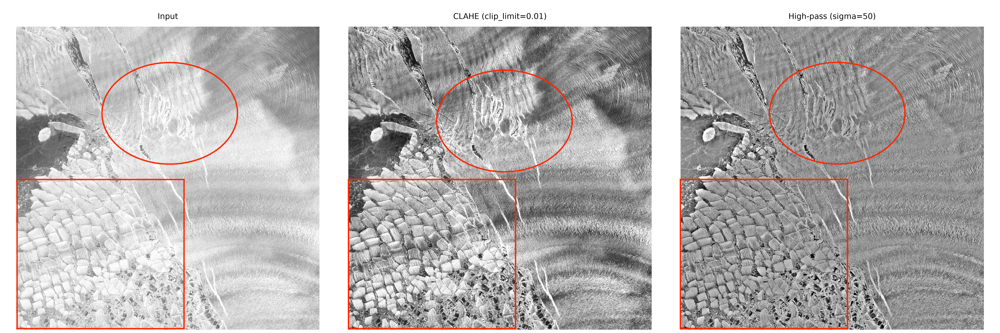

The second tile, r4 - c2, has three regions that I would like to comment on. The first square shows that CLAHE amplifies the background texture of the original tile (the wavy patterns) more than high-pass does. The other two squares show that CLAHE makes the crevasses brighter than the surroundings, while with high-pass the contrast is more subtle.

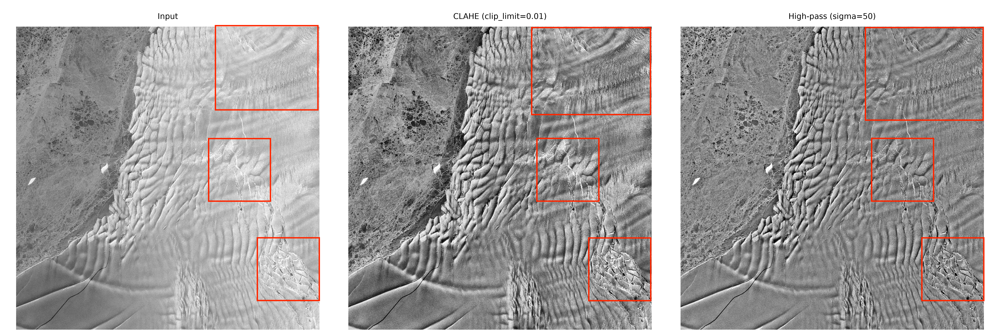

To summarize:

- **CLAHE:** gives stronger contrast, but it also amplifies the background texture and the noise.
- **High-pass (sigma=50):** gives a subtler result, with a flatter background and weaker wavy patterns. Some bright features end up close to the color of their surroundings.
- **Not decided yet:** there is no numerical metric and the data is not labeled, so neither method is validated. The next step is to test both on the tiles Emma recommends, and on a labeled example if she provides one. The team may also use both methods if they reveal different features.